# importing both the mp3 reduced dataset and the spotify de-duped one  
- (mp3_pbi)  ->> mp3_tracks
- (spotify_track_catalog) ->> ozp_tracks

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px # to add cursor hover-over info
import numpy as np

In [ ]:
# Load the de-duplicated spotify ctrack catalog (same as pbi/track_level like mp3 dataset)
ozp_tracks = pd.read_csv("/content/drive/MyDrive/spotify_track_catalog.csv")

In [ ]:
ozp_tracks.shape

(1625, 10)

In [ ]:
ozp_tracks.sample(2)

,ts,ms_played,master_metadata_track_name,master_metadata_album_artist_name,master_metadata_album_album_name,spotify_track_uri,clean_id,minutes_played,artist_mb,resolved_genre
876,2023-12-12 11:41:51+00:00,358387,Votiv,Dorisburg,Irrbloss,spotify:track:6L56pepR6uJYg4cQoG1W1n,6L56pepR6uJYg4cQoG1W1n,5.97,NaN,Other / Unknown
102,2022-06-04 11:39:22+00:00,234147,Northern Whale,"The Good, the Bad & the Queen","The Good, The Bad and The Queen",spotify:track:3vJFELMHiffCvYyrWFjzLp,3vJFELMHiffCvYyrWFjzLp,3.90,"The Good, the Bad & the Queen",Alternative


In [ ]:
# load the mp3 dataset used in powerbi (reduced columns)

mp3_tracks = pd.read_csv("/content/drive/MyDrive/mp3_pbi.csv")

In [ ]:
mp3_tracks.shape

(1015, 10)

In [ ]:
mp3_tracks.sample(2)

,tag_artist,artist_norm,tag_title,album,year,duration_secs,master_metadata_album_artist_name,artist_mb,resolved_genre,genre_source
118,Ojos de Brujo,ojos de brujo,Calé Barí,Bari,2004,317.283292,NaN,NaN,World,manual
739,ammoncontact,ammoncontact,Drops,Sounds Like Everything,2003,201.466667,NaN,NaN,Nu-Jazz,manual


## add normalised artist name column to spotify dataset

In [ ]:
ozp_tracks['artist_norm'] = ozp_tracks['master_metadata_album_artist_name'].str.strip().str.lower()

In [ ]:
ozp_tracks.tail()

,ts,ms_played,master_metadata_track_name,master_metadata_album_artist_name,master_metadata_album_album_name,spotify_track_uri,clean_id,minutes_played,artist_mb,resolved_genre,artist_norm
1620,2026-09-25 11:09:06+00:00,308600,Youth,Portico Quartet,Next Stop,spotify:track:7KK4ixxZE3K1I8MbR8dGcX,7KK4ixxZE3K1I8MbR8dGcX,5.14,Portico Quartet,Nu-Jazz,portico quartet
1621,2026-09-25 11:27:24+00:00,246946,Place of Two,Okvsho,Frozen Flashes,spotify:track:2mVQXLMuQCe6BiTrdLRbhf,2mVQXLMuQCe6BiTrdLRbhf,4.12,Okvsho,Nu-Jazz,okvsho
1622,2026-09-25 11:31:00+00:00,216232,Heavy Drops,Adam Ben Ezra,Heavy Drops,spotify:track:6oPs0wWiMnRohGOxyiv0rL,6oPs0wWiMnRohGOxyiv0rL,3.60,Adam Ben Ezra,Jazz,adam ben ezra
1623,2026-09-26 16:51:17+00:00,312383,Nightingale,Mammal Hands,Gift from the Trees,spotify:track:2WY3akDTRwojfbqQWNfSAP,2WY3akDTRwojfbqQWNfSAP,5.21,Mammal Hands,Post-Rock,mammal hands
1624,2026-09-26 17:17:41+00:00,189276,Last Words - Alternate Version,GoGo Penguin,Last Words / Fanfares,spotify:track:6ElFqNuymztw3XokCWBxkT,6ElFqNuymztw3XokCWBxkT,3.15,GoGo Penguin,Post-Rock,gogo penguin


# comparison of genre dispersion (violinplot)

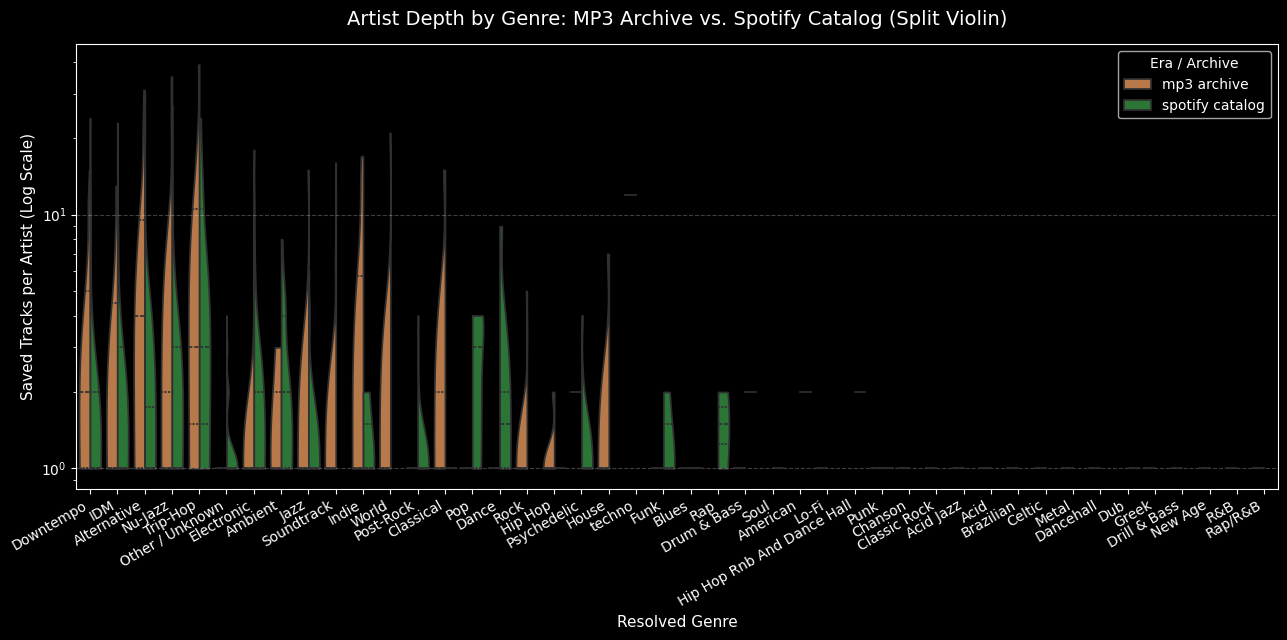

In [ ]:
# 1. Aggregate to (archive, genre, artist) level so each violin has a distribution of artists
mp3_artist_genre = (
    mp3_tracks
    .groupby(['resolved_genre', 'artist_norm'], as_index=False)
    .size()
    .rename(columns={'size': 'tracks_per_artist'})
)
mp3_artist_genre['archive'] = 'mp3 archive'

sp_artist_genre = (
    ozp_tracks
    .groupby(['resolved_genre', 'artist_norm'], as_index=False)
    .size()
    .rename(columns={'artist_norm': 'artist', 'size': 'tracks_per_artist'})
)
sp_artist_genre['archive'] = 'spotify catalog'

# join (concat) the 2 aggregated tables to use in the plot
df_violin = pd.concat([mp3_artist_genre, sp_artist_genre], ignore_index=True)

# order genres by combined total tracks (top 10 or all)
genre_order = (
    df_violin.groupby('resolved_genre')['tracks_per_artist']
    .sum()
    .sort_values(ascending=False)
    .index
)

# plot a split violinplot (mp3 on left side, Spotify on right)
plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(13, 6.5))

sns.violinplot(
    data = df_violin,
    x = 'resolved_genre',
    y = 'tracks_per_artist',
    hue = 'archive',
    order = genre_order,
    split = True,
    inner = 'quart',          # shows 25th, 50th (median), and 75th percentiles inside each half
    cut = 0,                  # prevents KDE from extending below 1 track
    density_norm = 'width',   # scales both halves to equal max width so smaller MP3 sample is clearly visible
    palette = {'mp3 archive': '#ca7638', 'spotify catalog': '#1f822e'},
    ax=ax
)

ax.set_yscale('log') # log scale keeps 1-track artists visible alongside 30-track discographies
ax.set_title('Artist Depth by Genre: MP3 Archive vs. Spotify Catalog (Split Violin)', fontsize=14, pad=14)
ax.set_xlabel('Resolved Genre', fontsize=11)
ax.set_ylabel('Saved Tracks per Artist (Log Scale)', fontsize=11)
plt.xticks(rotation = 30, ha = 'right')
ax.grid(axis = 'y', linestyle = '--', alpha=0.25)
ax.legend(title = 'Era / Archive', frameon=True)

plt.tight_layout()
plt.show()

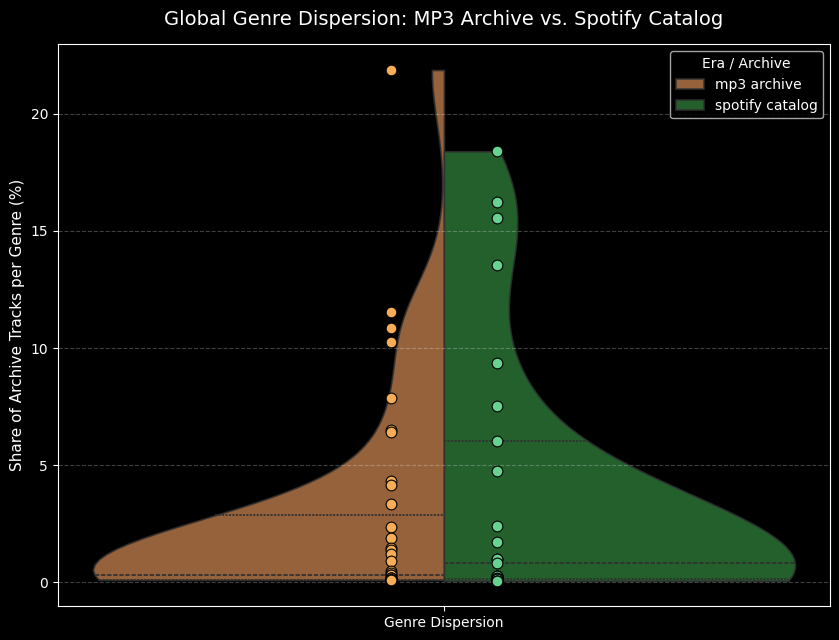

In [ ]:
# 1. Aggregate to 1 row per (archive, resolved_genre)
mp3_g = mp3_tracks['resolved_genre'].value_counts().reset_index()
mp3_g.columns = ['resolved_genre', 'track_count']
mp3_g['share_pct'] = (mp3_g['track_count'] / mp3_g['track_count'].sum()) * 100
mp3_g['archive'] = 'mp3 archive'

sp_g = ozp_tracks['resolved_genre'].value_counts().reset_index()
sp_g.columns = ['resolved_genre', 'track_count']
sp_g['share_pct'] = (sp_g['track_count'] / sp_g['track_count'].sum()) * 100
sp_g['archive'] = 'spotify catalog'

df_global = pd.concat([mp3_g, sp_g], ignore_index=True)
df_global['group'] = 'Genre Dispersion'  # single x-category for ONE unified split violin

# 2. Plot Single Split Violin
plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(8.5, 6.5))

palette_map = {'mp3 archive': '#ca7638', 'spotify catalog': '#1f822e'}

sns.violinplot(
    data=df_global,
    x='group',
    y='share_pct',          # swap to 'track_count' if you prefer raw track counts
    hue='archive',
    split=True,
    inner='quart',          # 25th, 50th (median), and 75th percentiles
    cut=0,
    density_norm='width',
    palette=palette_map,
    alpha=0.82,
    ax=ax
)

# Overlay each individual genre dot on its respective half
for arch, offset, dot_color in [('mp3 archive', -0.06, '#f6ad55'), ('spotify catalog', 0.06, '#68d391')]:
    sub = df_global[df_global['archive'] == arch]
    ax.scatter(
        np.repeat(0 + offset, len(sub)),
        sub['share_pct'],
        color=dot_color,
        edgecolor='black',
        linewidth=0.8,
        s=60,
        zorder=5
    )

ax.set_title('Global Genre Dispersion: MP3 Archive vs. Spotify Catalog', fontsize=14, pad=14)
ax.set_xlabel('')
ax.set_ylabel('Share of Archive Tracks per Genre (%)', fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.25)
ax.legend(title='Era / Archive', frameon=True)

plt.tight_layout()
plt.show()

/tmp/ipykernel_772/1659531352.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"{abs(int(x))}%" for x in xticks])


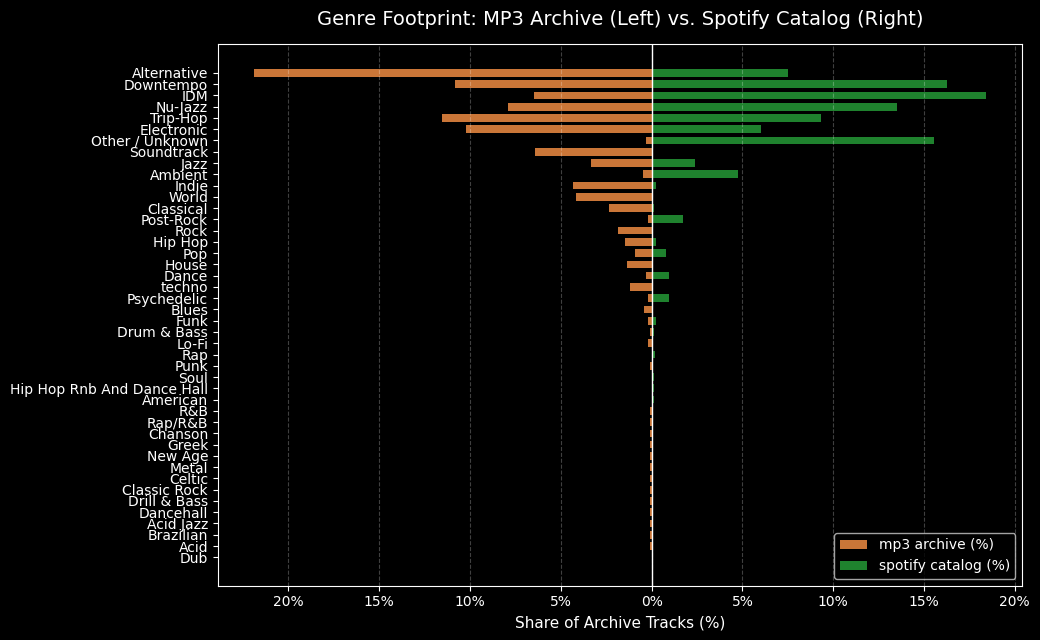

In [ ]:
# flip side-by-side and sort by combined share (largest at top)
piv = df_global.pivot(index='resolved_genre', columns='archive', values='share_pct').fillna(0)
piv['total'] = piv['mp3 archive'] + piv['spotify catalog']
piv = piv.sort_values('total', ascending=True)

plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(10.5, 6.5))

y = np.arange(len(piv))
ax.barh(y, -piv['mp3 archive'], color='#ca7638', height=0.68, label='mp3 archive (%)')
ax.barh(y, piv['spotify catalog'], color='#1f822e', height=0.68, label='spotify catalog (%)')

ax.axvline(0, color='white', linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(piv.index, fontsize=10)

# Display left-hand ticks as positive percentages
xticks = ax.get_xticks()
ax.set_xticklabels([f"{abs(int(x))}%" for x in xticks])

ax.set_title('Genre Footprint: MP3 Archive (Left) vs. Spotify Catalog (Right)', fontsize=14, pad=14)
ax.set_xlabel('Share of Archive Tracks (%)', fontsize=11)
ax.grid(axis='x', linestyle='--', alpha=0.25)
ax.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()


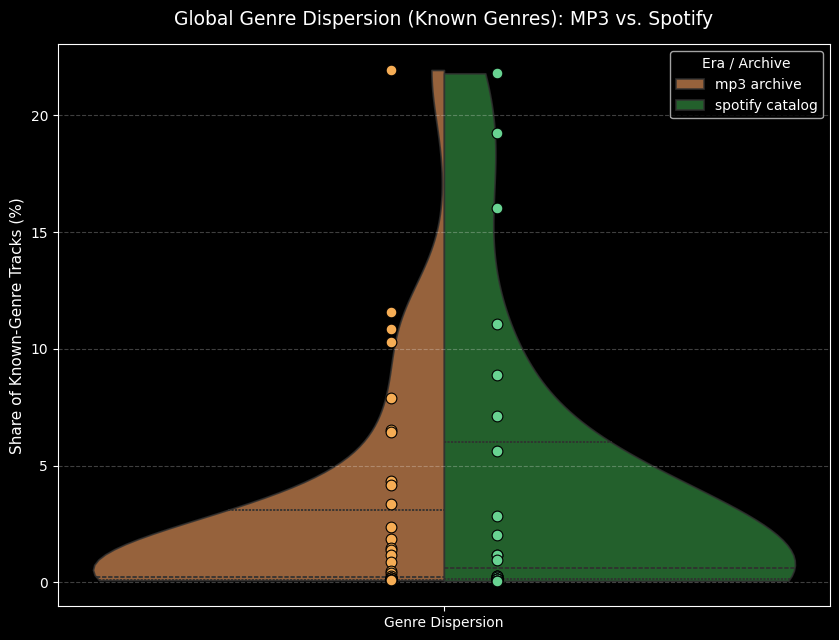

/tmp/ipykernel_772/1899892935.py:89: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"{abs(int(x))}%" for x in xticks])


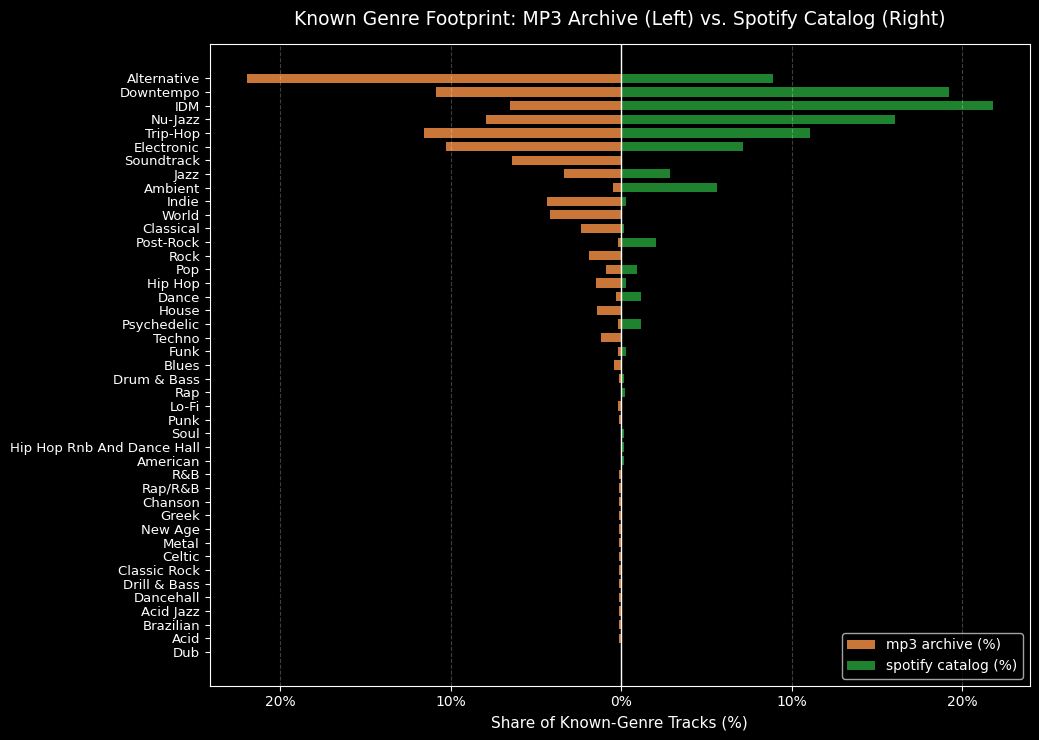

mp3 archive      (1,012 known tracks across 38 genres) -> Normalized Entropy: 0.689 | Effective Genres: 13.3
spotify catalog  (1,372 known tracks across 24 genres) -> Normalized Entropy: 0.587 | Effective Genres: 9.1


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Clean & exclude 'Other / Unknown' from both archives BEFORE computing shares
def prep_genre_counts(df, archive_label):
    clean_s = (
        df['resolved_genre']
        .dropna()
        .str.strip()
        .replace({'techno': 'Techno'})  # standardize casing if needed
    )
    clean_s = clean_s[clean_s != 'Other / Unknown']

    g = clean_s.value_counts().reset_index()
    g.columns = ['resolved_genre', 'track_count']
    g['share_pct'] = (g['track_count'] / g['track_count'].sum()) * 100
    g['archive'] = archive_label
    return g

mp3_g = prep_genre_counts(mp3_tracks, 'mp3 archive')
sp_g  = prep_genre_counts(ozp_tracks, 'spotify catalog')

df_global = pd.concat([mp3_g, sp_g], ignore_index=True)
df_global['group'] = 'Genre Dispersion'

# ==============================================================================
# CHART 1: Single Unified Split Violin (Excluding 'Other / Unknown')
# ==============================================================================
plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(8.5, 6.5))

palette_map = {'mp3 archive': '#ca7638', 'spotify catalog': '#1f822e'}

sns.violinplot(
    data=df_global,
    x='group',
    y='share_pct',
    hue='archive',
    split=True,
    inner='quart',
    cut=0,
    density_norm='width',
    palette=palette_map,
    alpha=0.82,
    ax=ax
)

for arch, offset, dot_color in [('mp3 archive', -0.06, '#f6ad55'), ('spotify catalog', 0.06, '#68d391')]:
    sub = df_global[df_global['archive'] == arch]
    ax.scatter(
        np.repeat(0 + offset, len(sub)),
        sub['share_pct'],
        color=dot_color,
        edgecolor='black',
        linewidth=0.8,
        s=60,
        zorder=5
    )

ax.set_title('Global Genre Dispersion (Known Genres): MP3 vs. Spotify', fontsize=13.5, pad=14)
ax.set_xlabel('')
ax.set_ylabel('Share of Known-Genre Tracks (%)', fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.25)
ax.legend(title='Era / Archive', frameon=True)

plt.tight_layout()
plt.show()

# ==============================================================================
# CHART 2: Mirrored Butterfly Chart (Excluding 'Other / Unknown')
# ==============================================================================
piv = df_global.pivot(index='resolved_genre', columns='archive', values='share_pct').fillna(0)
piv['total'] = piv['mp3 archive'] + piv['spotify catalog']
piv = piv.sort_values('total', ascending=True)

fig, ax = plt.subplots(figsize=(10.5, 7.5))

y = np.arange(len(piv))
ax.barh(y, -piv['mp3 archive'], color='#ca7638', height=0.68, label='mp3 archive (%)')
ax.barh(y, piv['spotify catalog'], color='#1f822e', height=0.68, label='spotify catalog (%)')

ax.axvline(0, color='white', linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(piv.index, fontsize=9.5)

xticks = ax.get_xticks()
ax.set_xticklabels([f"{abs(int(x))}%" for x in xticks])

ax.set_title('Known Genre Footprint: MP3 Archive (Left) vs. Spotify Catalog (Right)', fontsize=13.5, pad=14)
ax.set_xlabel('Share of Known-Genre Tracks (%)', fontsize=11)
ax.grid(axis='x', linestyle='--', alpha=0.25)
ax.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()

# ==============================================================================
# STAT CHECK: Shannon Entropy & Effective Genres (Excluding 'Other / Unknown')
# ==============================================================================
total_k = df_global['resolved_genre'].nunique()

for arch in ['mp3 archive', 'spotify catalog']:
    sub = df_global[df_global['archive'] == arch]
    shares = sub['track_count'] / sub['track_count'].sum()
    h_raw = -np.sum(shares * np.log2(shares))
    h_norm = h_raw / np.log2(total_k)
    eff_genres = 2 ** h_raw
    print(f"{arch:<16} ({sub['track_count'].sum():,} known tracks across {len(sub)} genres) -> "
          f"Normalized Entropy: {h_norm:.3f} | Effective Genres: {eff_genres:.1f}")

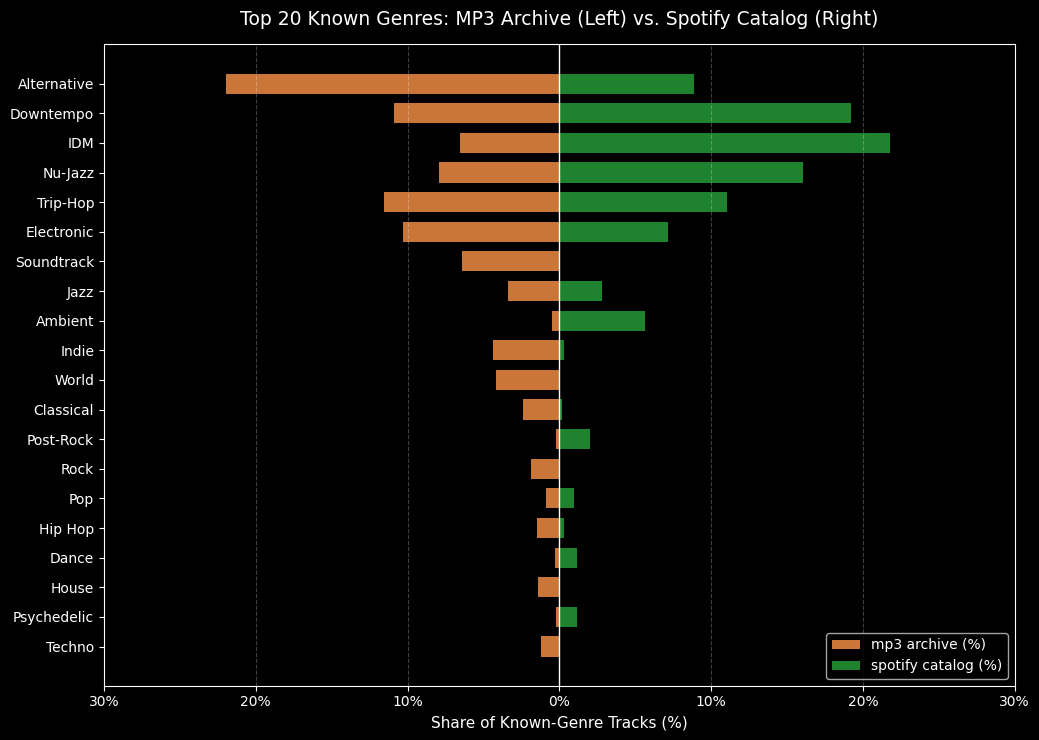

In [ ]:
#butterfly chart limited to top 20

# Pivot side-by-side (shares already calculated on full known-genre archives)
piv = df_global.pivot(index='resolved_genre', columns='archive', values='share_pct').fillna(0)
piv['total'] = piv['mp3 archive'] + piv['spotify catalog']

# Keep Top 20 by combined share, then sort ascending so the largest sits at the top of the barh plot
piv_top20 = piv.sort_values('total', ascending=False).head(20).sort_values('total', ascending=True)

plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(10.5, 7.5))

y = np.arange(len(piv_top20))
ax.barh(y, -piv_top20['mp3 archive'], color='#ca7638', height=0.68, label='mp3 archive (%)')
ax.barh(y, piv_top20['spotify catalog'], color='#1f822e', height=0.68, label='spotify catalog (%)')

ax.axvline(0, color='white', linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(piv_top20.index, fontsize=10)

# Lock tick positions before setting custom positive percentage labels
xticks = ax.get_xticks()
ax.set_xticks(xticks)
ax.set_xticklabels([f"{abs(int(x))}%" for x in xticks])

ax.set_title('Top 20 Known Genres: MP3 Archive (Left) vs. Spotify Catalog (Right)', fontsize=13.5, pad=14)
ax.set_xlabel('Share of Known-Genre Tracks (%)', fontsize=11)
ax.grid(axis='x', linestyle='--', alpha=0.25)
ax.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()

## plot used: genre comparison by duration (albumwraps)

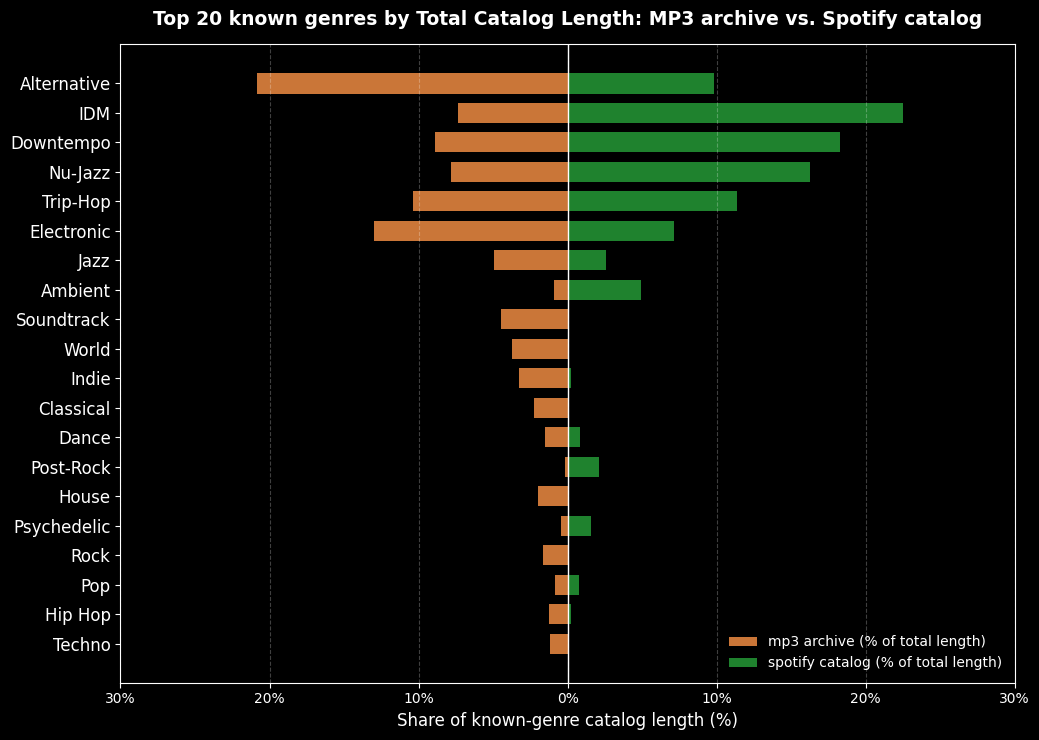

In [ ]:
# now measuring track length per genre (to capture albumwraps correctly):

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Aggregate total duration (in hours) per known genre for each archive
def prep_genre_duration(df, duration_col, archive_label, scale_to_hours=3600):
    temp = df[['resolved_genre', duration_col]].dropna().copy()
    temp['resolved_genre'] = temp['resolved_genre'].str.strip().replace({'techno': 'Techno'})
    temp = temp[temp['resolved_genre'] != 'Other / Unknown']

    g = (
        temp.groupby('resolved_genre', as_index=False)[duration_col]
        .sum()
        .rename(columns={duration_col: 'raw_dur'})
    )
    g['total_hours'] = g['raw_dur'] / scale_to_hours
    g['share_pct'] = (g['total_hours'] / g['total_hours'].sum()) * 100
    g['archive'] = archive_label
    return g

# mp3_tracks uses seconds (3600 sec/hr); ozp_tracks uses ms_played (3,600,000 ms/hr)
mp3_dur = prep_genre_duration(mp3_tracks, duration_col='duration_secs', archive_label='mp3 archive', scale_to_hours=3600)
sp_dur  = prep_genre_duration(ozp_tracks, duration_col='ms_played', archive_label='spotify catalog', scale_to_hours=3_600_000)

df_dur_global = pd.concat([mp3_dur, sp_dur], ignore_index=True)

# 2. Pivot & select Top 20 genres by combined duration share
piv_dur = df_dur_global.pivot(index='resolved_genre', columns='archive', values='share_pct').fillna(0)
piv_dur['total'] = piv_dur['mp3 archive'] + piv_dur['spotify catalog']

piv_dur_top20 = (
    piv_dur
    .sort_values('total', ascending=False)
    .head(20)
    .sort_values('total', ascending=True)
)

# 3. Plot Mirrored Butterfly Chart (Duration-Weighted Share %)
plt.style.use('dark_background')

bg_color = '#231b23' # (same as colour palette in slides)
fig.patch.set_facecolor(bg_color)  # Outer canvas / margin background
ax.set_facecolor(bg_color)         # Inner plot area background
fig, ax = plt.subplots(figsize=(10.5, 7.5))

y = np.arange(len(piv_dur_top20))
ax.barh(y, -piv_dur_top20['mp3 archive'], color='#ca7638', height=0.68, label='mp3 archive (% of total length)')
ax.barh(y, piv_dur_top20['spotify catalog'], color='#1f822e', height=0.68, label='spotify catalog (% of total length)')

ax.axvline(0, color='white', linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(piv_dur_top20.index, fontsize=12)

xticks = ax.get_xticks()
ax.set_xticks(xticks)
ax.set_xticklabels([f"{abs(int(x))}%" for x in xticks])

ax.set_title('Top 20 known genres by Total Catalog Length: MP3 archive vs. Spotify catalog', fontsize=13.5, pad=14, fontweight = 'bold')
ax.set_xlabel('Share of known-genre catalog length (%)', fontsize=12)
ax.grid(axis='x', linestyle='--', alpha=0.25)
ax.legend(loc='lower right', frameon=False)

plt.tight_layout()
plt.show()



In [ ]:
# and the shannon entropy also weighted by duration rather than track count

# 4. Duration-Weighted Shannon Entropy Check
total_k = df_dur_global['resolved_genre'].nunique()
for arch in ['mp3 archive', 'spotify catalog']:
    sub = df_dur_global[df_dur_global['archive'] == arch]
    shares = sub['total_hours'] / sub['total_hours'].sum()
    h_raw = -np.sum(shares * np.log2(shares))
    h_norm = h_raw / np.log2(total_k)
    eff_genres = 2 ** h_raw
    print(f"{arch:<16} ({sub['total_hours'].sum():.1f} hrs across {len(sub)} genres) -> "
          f"Normalized Entropy: {h_norm:.3f} | Effective Genres: {eff_genres:.1f}")

mp3 archive      (74.9 hrs across 38 genres) -> Normalized Entropy: 0.707 | Effective Genres: 14.3
spotify catalog  (93.9 hrs across 24 genres) -> Normalized Entropy: 0.582 | Effective Genres: 8.9


#new artist discovery

In [ ]:
print("mp3_tracks: ", mp3_tracks.columns)
print("ozp_tracks: ", ozp_tracks.columns)

mp3_tracks:  Index(['tag_artist', 'artist_norm', 'tag_title', 'album', 'year',
       'duration_secs', 'master_metadata_album_artist_name', 'artist_mb',
       'resolved_genre', 'genre_source'],
      dtype='object')
ozp_tracks:  Index(['ts', 'ms_played', 'master_metadata_track_name',
       'master_metadata_album_artist_name', 'master_metadata_album_album_name',
       'spotify_track_uri', 'clean_id', 'minutes_played', 'artist_mb',
       'resolved_genre', 'artist_norm'],
      dtype='object')


initial metrics of new and discovered

In [ ]:
# start with clean, non-null artist sets, using artist_norm
mp3_artists = set(mp3_tracks['artist_norm'].dropna().str.strip())
sp_artists  = set(ozp_tracks['artist_norm'].dropna().str.strip())

retained_artists = mp3_artists & sp_artists      # in BOTH datasets
mp3_only_artists = mp3_artists - sp_artists      # left behind in MP3 era
net_new_artists  = sp_artists - mp3_artists      # discovered in Spotify era

print(f"Total unique artists across both archives: {len(mp3_artists | sp_artists):,}")
print(f"  • MP3 Archive total artists:     {len(mp3_artists):,}")
print(f"  • Spotify Catalog total artists: {len(sp_artists):,}")
print("-" * 50)
print(f"  • Retained (MP3 -> Spotify):     {len(retained_artists):,} ({len(retained_artists)/len(mp3_artists)*100:.1f}% of MP3 artists retained)")
print(f"  • MP3-Only (Did not carry over): {len(mp3_only_artists):,} ({len(mp3_only_artists)/len(mp3_artists)*100:.1f}% of MP3 artists)")
print(f"  • Net-New on Spotify:            {len(net_new_artists):,} ({len(net_new_artists)/len(sp_artists)*100:.1f}% of Spotify roster is brand new)")

Total unique artists across both archives: 1,022
  • MP3 Archive total artists:     339
  • Spotify Catalog total artists: 743
--------------------------------------------------
  • Retained (MP3 -> Spotify):     60 (17.7% of MP3 artists retained)
  • MP3-Only (Did not carry over): 279 (82.3% of MP3 artists)
  • Net-New on Spotify:            683 (91.9% of Spotify roster is brand new)


defining artists as legacy (mp3) or net-new (spotify discovery) in artist_discovery table.

In [ ]:
# checking 'ts' is datetime
ozp_tracks['ts'] = pd.to_datetime(ozp_tracks['ts'])

# find first appearance per artist on Spotify
artist_discovery = (ozp_tracks
    .dropna(subset=['artist_norm'])
    .groupby('artist_norm', as_index=False)
    .agg(
        first_seen=('ts', 'min'),
        sp_tracks=('master_metadata_track_name', 'count'),
        sp_hours=('ms_played', lambda x: x.sum() / 3_600_000),
        primary_genre=('resolved_genre', lambda x: x.mode().iloc[0] if not x.mode().empty else 'Unknown')))

# tag each Spotify artist as 'Legacy (from mp3)' or 'Net-new (Spotify discovery)'
artist_discovery['origin'] = np.where(
    artist_discovery['artist_norm'].isin(mp3_artists),
    'Legacy (from mp3)',
    'Net-new (Spotify discovery)')

artist_discovery['discovery_year'] = artist_discovery['first_seen'].dt.year

## plot used: yearly artist discovery

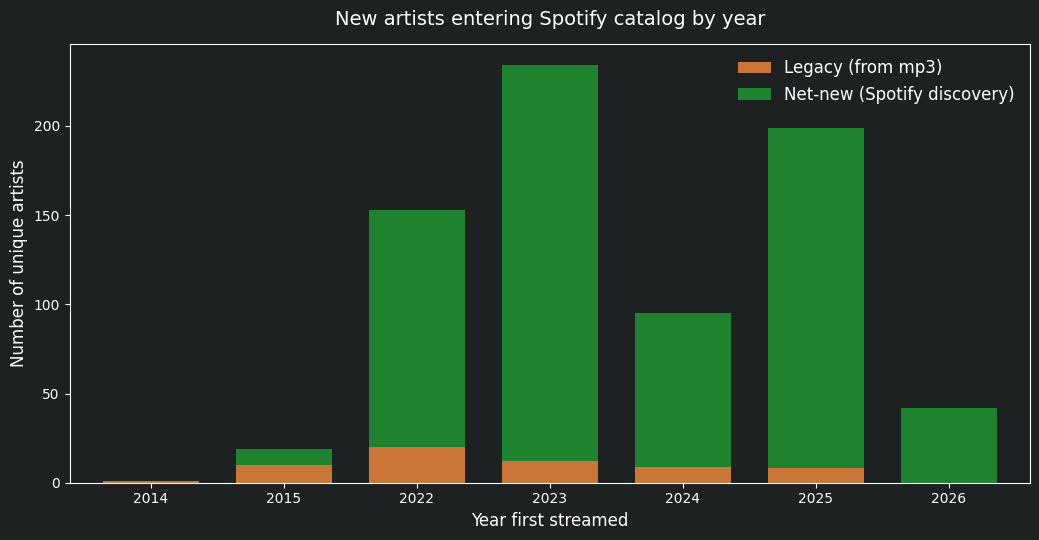

In [ ]:
# plot stacked yearly artist discovery
yearly_disc = (
    artist_discovery
    .groupby(['discovery_year', 'origin'])
    .size()
    .unstack(fill_value=0))

#style and setup
plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(10.5, 5.5))
bg_color = '#1d2121'
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

# plot using spotify and mp3 colours
yearly_disc.plot(
    kind = 'bar',
    stacked = True,
    color = {'Legacy (from mp3)': '#ca7638', 'Net-new (Spotify discovery)': '#1f822e'},
    width = 0.72,
    ax = ax)


ax.set_title('New artists entering Spotify catalog by year', fontsize=14, pad=14)
ax.set_xlabel('Year first streamed', fontsize=12)
ax.set_ylabel('Number of unique artists', fontsize=12)
plt.xticks(rotation=0)
# ax.grid(axis='y', linestyle='--', alpha=0.25)
ax.legend(title= False, fontsize=12, frameon = False)

plt.tight_layout()
plt.show()

In [ ]:
yearly_disc.head(2)

origin,Legacy (from mp3),Net-new (Spotify discovery)
discovery_year,,
2014,1,0
2015,10,9


# SAVE artist_discovery df (complete / tidy-up) to take over to powerbi:

In [ ]:
ozp_tracks['ts'].dtype

datetime64[ns, UTC]

In [ ]:
# aggregate Spotify metrics per artist_norm
sp_artist_agg = (
    ozp_tracks
    .dropna(subset=['artist_norm'])
    .groupby('artist_norm', as_index=False)
    .agg(
        display_artist=('master_metadata_album_artist_name', 'first'),
        first_seen=('ts', 'min'),
        last_seen_catalog=('ts', 'max'),
        sp_tracks=('master_metadata_track_name', 'count'),
        sp_catalog_hours=('ms_played', lambda x: x.sum() / 3_600_000),
        sp_resolved_genre=('resolved_genre', lambda x: x.mode().iloc[0] if not x.mode().empty else 'Other / Unknown')))

# aggregate mp3 metrics per artist_norm
mp3_artist_agg = (
    mp3_tracks
    .dropna(subset=['artist_norm'])
    .groupby('artist_norm', as_index=False)
    .agg(
        mp3_display_artist=('tag_artist', 'first'),
        mp3_tracks=('tag_title', 'count'),
        mp3_hours=('duration_secs', lambda x: x.sum() / 3600),
        mp3_resolved_genre=('resolved_genre', lambda x: x.mode().iloc[0] if not x.mode().empty else 'Other / Unknown')))

# outer-merge both archives to make sure all artists included
artist_discovery_pbi = pd.merge(
    sp_artist_agg,
    mp3_artist_agg,
    on = 'artist_norm',
    how = 'outer')

# clean display name & resolved genre fallback (prefer Spotify, fall back to mp3)
artist_discovery_pbi['display_artist'] = artist_discovery_pbi['display_artist'].fillna(artist_discovery_pbi['mp3_display_artist'])
artist_discovery_pbi['resolved_genre'] = artist_discovery_pbi['sp_resolved_genre'].fillna(artist_discovery_pbi['mp3_resolved_genre'])

# fill missing counts/hours with 0
for col in ['sp_tracks', 'mp3_tracks']:
    artist_discovery_pbi[col] = artist_discovery_pbi[col].fillna(0).astype(int)

for col in ['sp_catalog_hours', 'mp3_hours']:
    artist_discovery_pbi[col] = artist_discovery_pbi[col].fillna(0).round(2)

# classify Artist Origin / Lifecycle Status
conditions = [
    (artist_discovery_pbi['mp3_tracks'] > 0) & (artist_discovery_pbi['sp_tracks'] > 0),
    (artist_discovery_pbi['mp3_tracks'] == 0) & (artist_discovery_pbi['sp_tracks'] > 0),
    (artist_discovery_pbi['mp3_tracks'] > 0) & (artist_discovery_pbi['sp_tracks'] == 0)
]
choices = [
    'Legacy (from mp3)',
    'Net-new (Spotify discovery)',
    'mp3-only (left behind)'
]
artist_discovery_pbi['origin_status'] = np.select(conditions, choices, default='Unknown')

# powerbi-friendly Date & Depth Tier columns
artist_discovery_pbi['first_seen_date'] = artist_discovery_pbi['first_seen'].dt.strftime('%Y-%m-%d')
artist_discovery_pbi['discovery_year'] = artist_discovery_pbi['first_seen'].dt.year.astype('Int64')
artist_discovery_pbi['discovery_year_month'] = artist_discovery_pbi['first_seen'].dt.strftime('%Y-%m')

artist_discovery_pbi['sp_depth_tier'] = pd.cut(
    artist_discovery_pbi['sp_tracks'],
    bins=[-1, 0, 1, 3, 9, 9999],
    labels=['0 (mp3 only)', '1 track', '2–3 tracks', '4–9 tracks', '10+ tracks']
)

# drop helper columns and export
cols_final = [
    'artist_norm', 'display_artist', 'origin_status', 'resolved_genre',
    'first_seen_date', 'discovery_year', 'discovery_year_month',
    'sp_tracks', 'sp_catalog_hours', 'sp_depth_tier',
    'mp3_tracks', 'mp3_hours'
]
artist_discovery_pbi = artist_discovery_pbi[cols_final]

display(artist_discovery_pbi.head(10))


,artist_norm,display_artist,origin_status,resolved_genre,first_seen_date,discovery_year,discovery_year_month,sp_tracks,sp_catalog_hours,sp_depth_tier,mp3_tracks,mp3_hours
0,28 days later soundtrack,28 Days Later Soundtrack,mp3-only (left behind),Soundtrack,NaN,<NA>,NaN,0,0.00,0 (mp3 only),1,0.03
1,300 original motion picture soundtrack,300 Original Motion Picture Soundtrack,mp3-only (left behind),Soundtrack,NaN,<NA>,NaN,0,0.00,0 (mp3 only),7,0.27
2,36,36,Net-new (Spotify discovery),IDM,2023-11-17,2023,2023-11,1,0.04,1 track,0,0.00
3,40 thieves,40 Thieves,Net-new (Spotify discovery),Nu-Jazz,2025-10-28,2025,2025-10,1,0.08,1 track,0,0.00
4,40 winks,40 Winks,Net-new (Spotify discovery),Nu-Jazz,2023-08-03,2023,2023-08,7,0.33,4–9 tracks,0,0.00
5,44th move,44th Move,Net-new (Spotify discovery),Other / Unknown,2023-10-05,2023,2023-10,1,0.04,1 track,0,0.00
6,700 feel,700 Feel,Net-new (Spotify discovery),Other / Unknown,2025-01-31,2025,2025-01,1,0.07,1 track,0,0.00
7,808 state,808 State,Net-new (Spotify discovery),IDM,2023-01-25,2023,2023-01,1,0.10,1 track,0,0.00
8,9 lazy 9,9 Lazy 9,Net-new (Spotify discovery),Nu-Jazz,2022-07-22,2022,2022-07,21,1.45,10+ tracks,0,0.00
9,a band called success,A Band Called Success,Net-new (Spotify discovery),Alternative,2025-07-13,2025,2025-07,1,0.09,1 track,0,0.00


In [ ]:
# save as csv to download and take to pbi
artist_discovery_pbi.to_csv('/content/drive/MyDrive/artist_discovery_pbi.csv', index=False)

In [ ]:
# checking which ones I "discovered" in 2025 (from mp3s)!!
artist_discovery_pbi.loc[(artist_discovery_pbi['origin_status'] == 'Legacy (from mp3)') & (artist_discovery_pbi['discovery_year'] == 2025), ['artist_norm', 'sp_depth_tier']]

,artist_norm,sp_depth_tier
102,black eyed peas,1 track
292,faithless,1 track
360,gorillaz,2–3 tracks
401,hooverphonic,1 track
533,lemon jelly,4–9 tracks
564,luke vibert,1 track
633,morphine,1 track
835,soul ii soul,1 track
